<a href="https://colab.research.google.com/github/anniiexp/MAT422/blob/main/3_2_Limits%2C_Derivatives%2C_Taylor.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# MAT422 - Section 3.2: Limits, Derivatives, and Taylor's Theorem

## Topics:


*   Limits and continuity
*   Derivatives
*   Taylor's theorem



In [10]:
import numpy as np
import matplotlib.pyplot as plt

np.set_printoptions(precision=6, suppress=True)

# 3.2.1 Limits and Continuity

A limit is the value a function gets to as x gets close to a number. We can approach the number from the left (smaller x values) or from the right (bigger x values). The limit only exists if both sides head toward the same value.
A function is continuous at a point if:


1.   The function has a value there,
2.   The limit exists there, and
3.   The limit equals the function's value.

In other terms, a person could draw the graph through that point without lifting the pencil, so there are no holes or no jumps.





h: [0.5   0.1   0.01  0.001]
(e^h - 1)/h: [1.297443 1.051709 1.005017 1.0005  ]


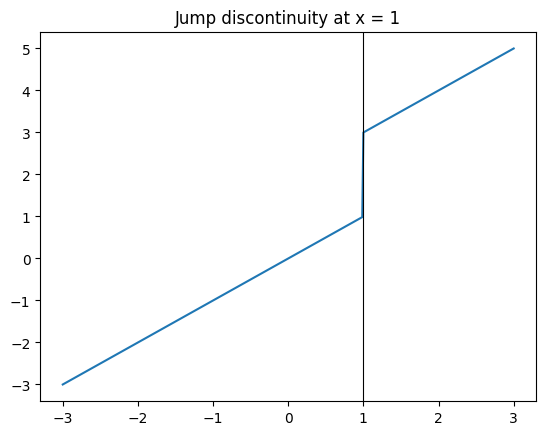

In [11]:
# example 1: a limit
h = np.array([0.5, 0.1, 0.01, 0.001])
print("h:", h)
print("(e^h - 1)/h:", (np.exp(h) - 1) / h)

# example 2: a jump discontinuity
x = np.linspace(-3, 3, 400)
y = np.where(x < 1, x, x + 2)
plt.plot(x, y)
plt.axvline(1, color="black", linewidth=0.8)
plt.title("Jump discontinuity at x = 1")
plt.show()

Example 1: The printed values are about 1.297, 1.052, 1.005, 1.0005. Each time h gets smaller, the answer gets closer to 1. Even though we can't plug in $h = 0$ directly, the numbers show that the limit is 1. This is the key idea of a limit: it's about where the function is heading, now what happens exactly at the point.


Example 2: Coming from the left, the graph follows $y = x$ so it gets close to 1. Coming from the right, $y = x + 2$, so it starts at 3. The two sides don't meet so the graph has a jump at $x = 1$. Because the left and right limits are different, the limit doesn't exist, which means the function isn't continuous at $x = 1$

# 3.2.2 Derivatives

The derivative of a function at a point tells us how fast the function is changing there. On a graph, it's the slope of a tangent line, the straight that just touches the curve at that point.
The derivative is defined using a limit:

$$f'(x) = \lim_{h \to 0} \frac{f(x+h) - f(x)}{h}$$
We take the slope between two points that are very close together, then let the distance h shrink to $0$.


step sizes h:         [0.1    0.01   0.001  0.0001]
numeric estimates:    [8.01     8.0001   8.000001 8.      ]
exact derivative:     8
errors:               [0.01     0.0001   0.000001 0.      ]


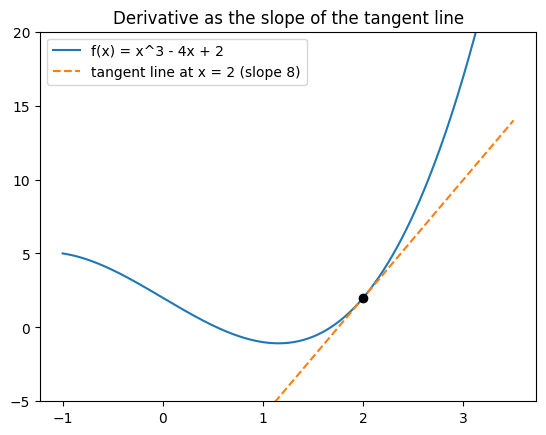

In [12]:
def f(x):
  return x**3 - 4*x + 2

point = 2
steps = np.array([1e-1, 1e-2, 1e-3, 1e-4])

# estimate the slope using points just left and right of x = 2
numeric_derivatives = (f(point + steps) - f(point - steps)) / (2 * steps)

# exact derivative from the power rule: f'(x) = 3x^2 - 4
exact_derivative = 3 * point**2 - 4

print("step sizes h:        ", steps)
print("numeric estimates:   ", numeric_derivatives)
print("exact derivative:    ", exact_derivative)
print("errors:              ", np.abs(numeric_derivatives - exact_derivative))

# Plot the function and its tangent line at x = 2
x = np.linspace(-1, 3.5, 400)
tangent = f(point) + exact_derivative * (x - point)
plt.plot(x, f(x), label="f(x) = x^3 - 4x + 2")
plt.plot(x, tangent, "--", label="tangent line at x = 2 (slope 8)")
plt.plot(point, f(point), "ko")
plt.ylim(-5, 20)
plt.legend()
plt.title("Derivative as the slope of the tangent line")
plt.show()

The estimates are about 8.01, 8.0001, 8.000001, and 8.0. As the step size h gets smaller, the estimates get closer to the exact derivative of 8. This shows that the derivative really is a limit, where the slope and between 2 nearby points approaches the true slope as the points get closer together.

The errors also shrink quickly, each time h gets $10$ times smaller the error gets about $100$ times smaller $(0.01...0.0001....0.0000001)$. This means the central difference is a very accurate way to estimate a derivative.

In the plot, the dashes tangent line touches the curve at $x = 2$ and has a slope of $8$. Near that point, the curve and the line almost match. The function is increasing, rising about $8$ units for every $1$ unit to the right.

# 3.3.3 Taylor's Theorem

Taylor's theorem says that a smooth function can be approximated near a point by a **polynomial**. The polynomial is built from the function's derivatives at that point:
$$f(x) \approx f(a) + f'(a)(x-a) + \frac{f''(a)}{2!}(x-a)^2 + \frac{f'''(a)}{3!}(x-a)^3 + \cdots$$

This is called a **Taylor polynomial**. Using more terms (a higher degree) usually makes the approximation better. Taylor's theorem also tells us how big the error can be. If every derivative of $f$ is at most 1 in size, then the error of a degree-$n$ Taylor polynomial at $a = 0$ is at most
$$\text{error} \le \frac{|x|^{n+1}}{(n+1)!}$$



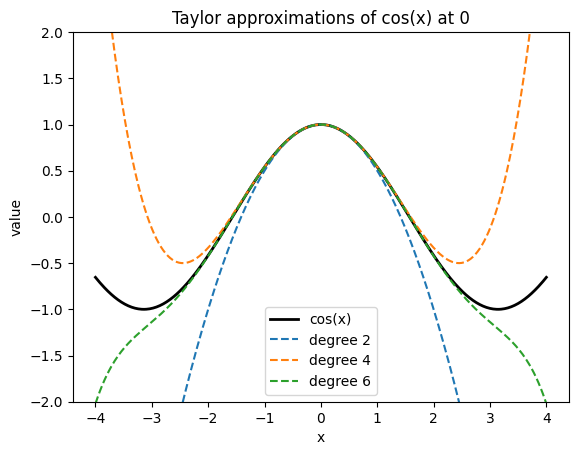

degree 2: max error = 0.040302,  bound = 0.166667
degree 4: max error = 0.001364,  bound = 0.008333
degree 6: max error = 0.000025,  bound = 0.000198


In [13]:
from math import factorial

# taylor polynomial for cos(x) centered at 0, up to a given degree
def taylor_cos(x, degree):
  total = 0
  for k in range(0, degree + 1, 2):
    total += (-1)**(k // 2) * x**k / factorial(k)
  return total

# plot cos(x) against taylor polynomial of degree 2, 4, and 6
x = np.linspace(-4, 4, 400)
plt.plot(x, np.cos(x), "k", linewidth=2, label="cos(x)")
for degree in [2, 4, 6]:
    plt.plot(x, taylor_cos(x, degree), "--", label=f"degree {degree}")
plt.ylim(-2, 2)
plt.xlabel("x")
plt.ylabel("value")
plt.title("Taylor approximations of cos(x) at 0")
plt.legend()
plt.show()

# checking actual max error on [-1, 1] vs the error bound from taylor theorem
x_check = np.linspace(-1, 1, 201)
for degree in [2, 4, 6]:
    error = np.max(np.abs(np.cos(x_check) - taylor_cos(x_check, degree)))
    bound = 1 / factorial(degree + 1)        # |x| <= 1, so |x|^(n+1) <= 1
    print(f"degree {degree}: max error = {error:.6f},  bound = {bound:.6f}")

In the plot, all three Taylor polynomials match $\cos(x)$ very closely near $x = 0$. As we move farther from 0, they start to drift away. The degree 2 polynomial pulls away first, and the degree 6 polynomial stays close to $\cos(x)$ the longest. More terms mean give a better approximation over a wider range.

The printed errors on $[-1, 1]$ are about:
- degree 2: 0.040302
- degree 4: 0.001364
- degree 6: 0.000025

Each time I add more terms, the error drops a lot. In every case, the actual error is smaller than the bound from Taylor's theorem, which confirms that the theorem's error estimate works.


# Reflection



*   - **Limits and continuity:** Used $(e^h - 1)/h$ with $h$ values from 0.5 down to 0.001 and printed the results, which approached 1. Plotted a piecewise function with a jump at $x = 1$, where the left side approached 1 and the right side approached 3. This showed that a limit only exists when both sides match, and a function is continuous only when there is no gap or jump.

*   - **Derivatives:** Used $f(x) = x^3 - 4x + 2$ at $x = 2$, where the exact derivative is 8. Compared central difference estimates for step sizes from 0.1 to 0.0001, and the error shrank from 0.01 to almost 0. The tangent line plot showed the derivative as the slope of the curve at that point.



*   - **Taylor's theorem:** Approximated $\cos(x)$ at 0 with Taylor polynomials of degree 2, 4, and 6. The max errors on $[-1, 1]$ were 0.040302, 0.001364, and 0.000025, all below the error bounds from Taylor's theorem. The plot showed that higher-degree polynomials stayed close to $\cos(x)$ over a wider range.


